In [1]:
import osmnx as ox

import pandas as pd
import geopandas as gpd
import shapely
import pyrosm

pd.set_option("display.max_columns", None)

In [2]:
fp = "chile-latest.osm.pbf"
place_name = "Concepción, Chile"

place_string = "_".join(place_name.lower().split(",")[0].split(" "))

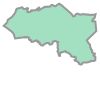

In [3]:
area_gdf = ox.geocode_to_gdf(place_name)
area = area_gdf.geometry.iloc[0]
area

In [4]:
# define the keys you want to query through a <key>: <value> dict

# the <value> for each <key> can be a list (i.e. ["hospital", "pharmacy"])
# also it can be True if you want to download all features with <key>

tags = {
    "amenity": True
    # add other keys like "shop": True if you want
}

In [5]:
# load the file with all osm data and clip with boundary
osm = pyrosm.OSM(fp, bounding_box=area)

# download the features
pois = osm.get_pois(custom_filter=tags)

pois = pois.to_crs(32718)
pois.geometry = pois.geometry.centroid
pois = pois.to_crs(4326)

pois = pois[~pois["amenity"].isna()]
pois = pois[pois['amenity'] != 'bench']

pois.lon = pois.geometry.x
pois.lat = pois.geometry.y
pois = pois.rename(columns={"lon": "x", "lat": "y"})

pois = pois[["id", "x", "y", "amenity", "geometry"]]

In [119]:
edges_gdf = gpd.read_file("./network/provincia_de_concepción.gpkg", layer="edges", encoding="latin-1")

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

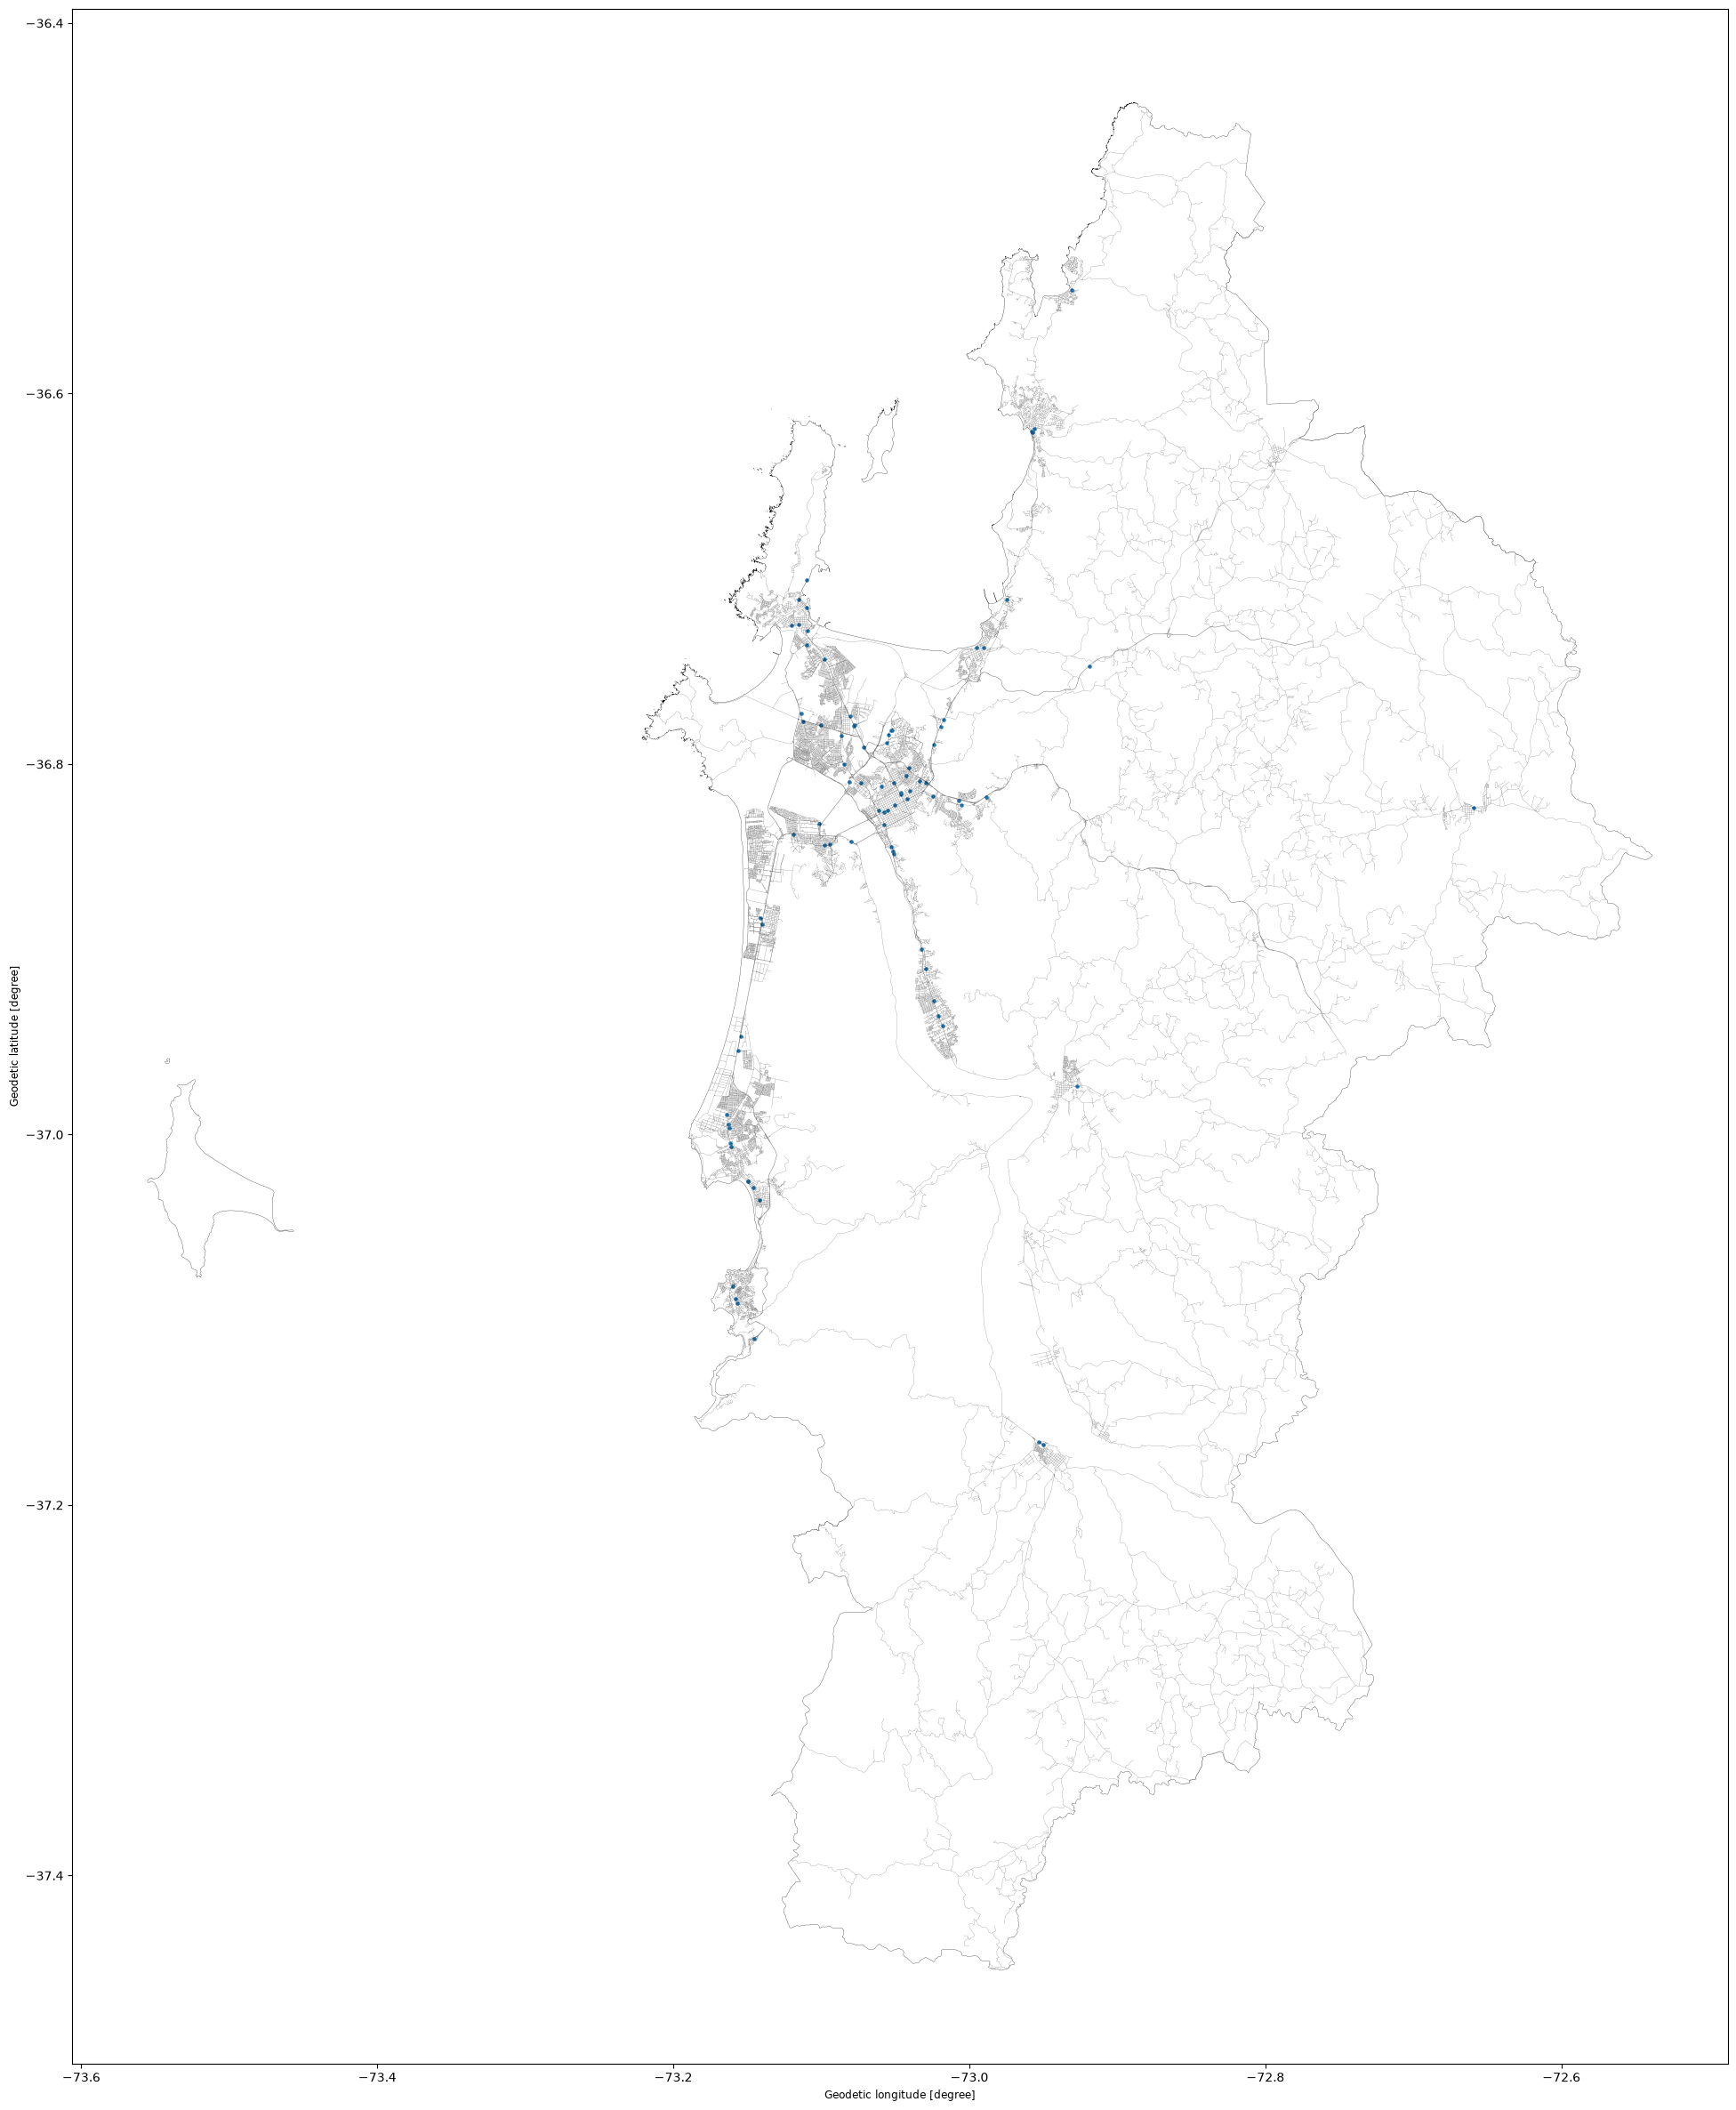

In [140]:
ax = pois[pois.amenity == "fuel"].plot(figsize=(30,30), markersize=5)
edges_gdf.plot(ax=ax, color="black", linewidth=0.1)
area_gdf.plot(ax=ax, color="none", linewidth=0.2)

In [6]:
pois.to_parquet(f"pois/pois_{place_string}.parquet")